In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    roc_curve,
    silhouette_score
)

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.keras.utils.set_random_seed(42)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [ ]:
from google.colab import files

uploaded = files.upload()
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

if df.shape[1] == 1:
    df = pd.read_csv(filename, sep=";")

print("Loaded file:", filename)
print("Dataset shape:", df.shape)
df.head()

Saving Bank Marketing.csv to Bank Marketing.csv
Loaded file: Bank Marketing.csv
Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
print("Number of data points:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Number of input features:", df.shape[1] - 1)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Number of data points: 41188
Number of columns: 21
Number of input features: 20

Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-nul

In [ ]:
duplicate_count = df.duplicated().sum()
print("Duplicate rows found:", duplicate_count)

df = df.drop_duplicates().reset_index(drop=True)

object_columns = df.select_dtypes(include="object").columns
for col in object_columns:
    df[col] = df[col].replace(r"^\s*$", np.nan, regex=True)

print("Shape after duplicate removal:", df.shape)

Duplicate rows found: 12
Shape after duplicate removal: (41176, 21)


In [ ]:
numerical_features = df.select_dtypes(include=np.number).columns.tolist()
categorical_features = df.select_dtypes(include="object").columns.tolist()

print("Numerical features:", len(numerical_features))
print(numerical_features)

print("\nCategorical features (including target y):", len(categorical_features))
print(categorical_features)

Numerical features: 10
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical features (including target y): 11
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']


In [ ]:
for col in categorical_features:
    print(f"{col}: {df[col].nunique(dropna=False)} unique values")
    print(df[col].value_counts(dropna=False))
    print("-" * 60)

job: 12 unique values
job
admin.           10419
blue-collar       9253
technician        6739
services          3967
management        2924
retired           1718
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64
------------------------------------------------------------
marital: 4 unique values
marital
married     24921
single      11564
divorced     4611
unknown        80
Name: count, dtype: int64
------------------------------------------------------------
education: 8 unique values
education
university.degree      12164
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4176
basic.6y                2291
unknown                 1730
illiterate                18
Name: count, dtype: int64
------------------------------------------------------------
default: 3 unique values
default
no         32577
unknown     8

,Count,Percentage
y,,
no,36537,88.73
yes,4639,11.27


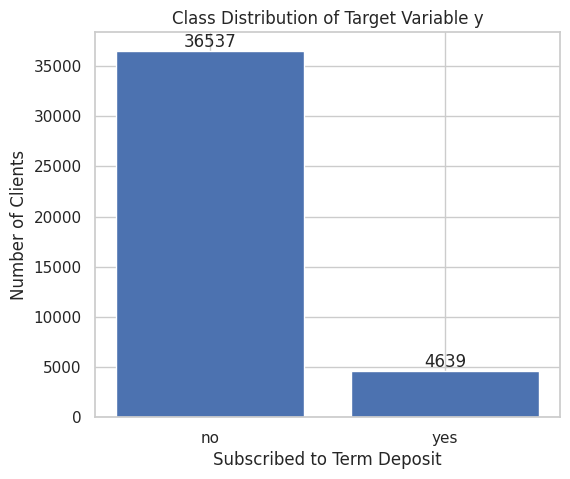

In [ ]:
class_counts = df["y"].value_counts()
class_percent = df["y"].value_counts(normalize=True) * 100

imbalance_df = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percent.round(2)
})

display(imbalance_df)

plt.figure(figsize=(6, 5))
ax = plt.bar(class_counts.index, class_counts.values)
plt.title("Class Distribution of Target Variable y")
plt.xlabel("Subscribed to Term Deposit")
plt.ylabel("Number of Clients")

for bar in ax:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        int(bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.show()

Encoded correlation matrix shape: (55, 55)


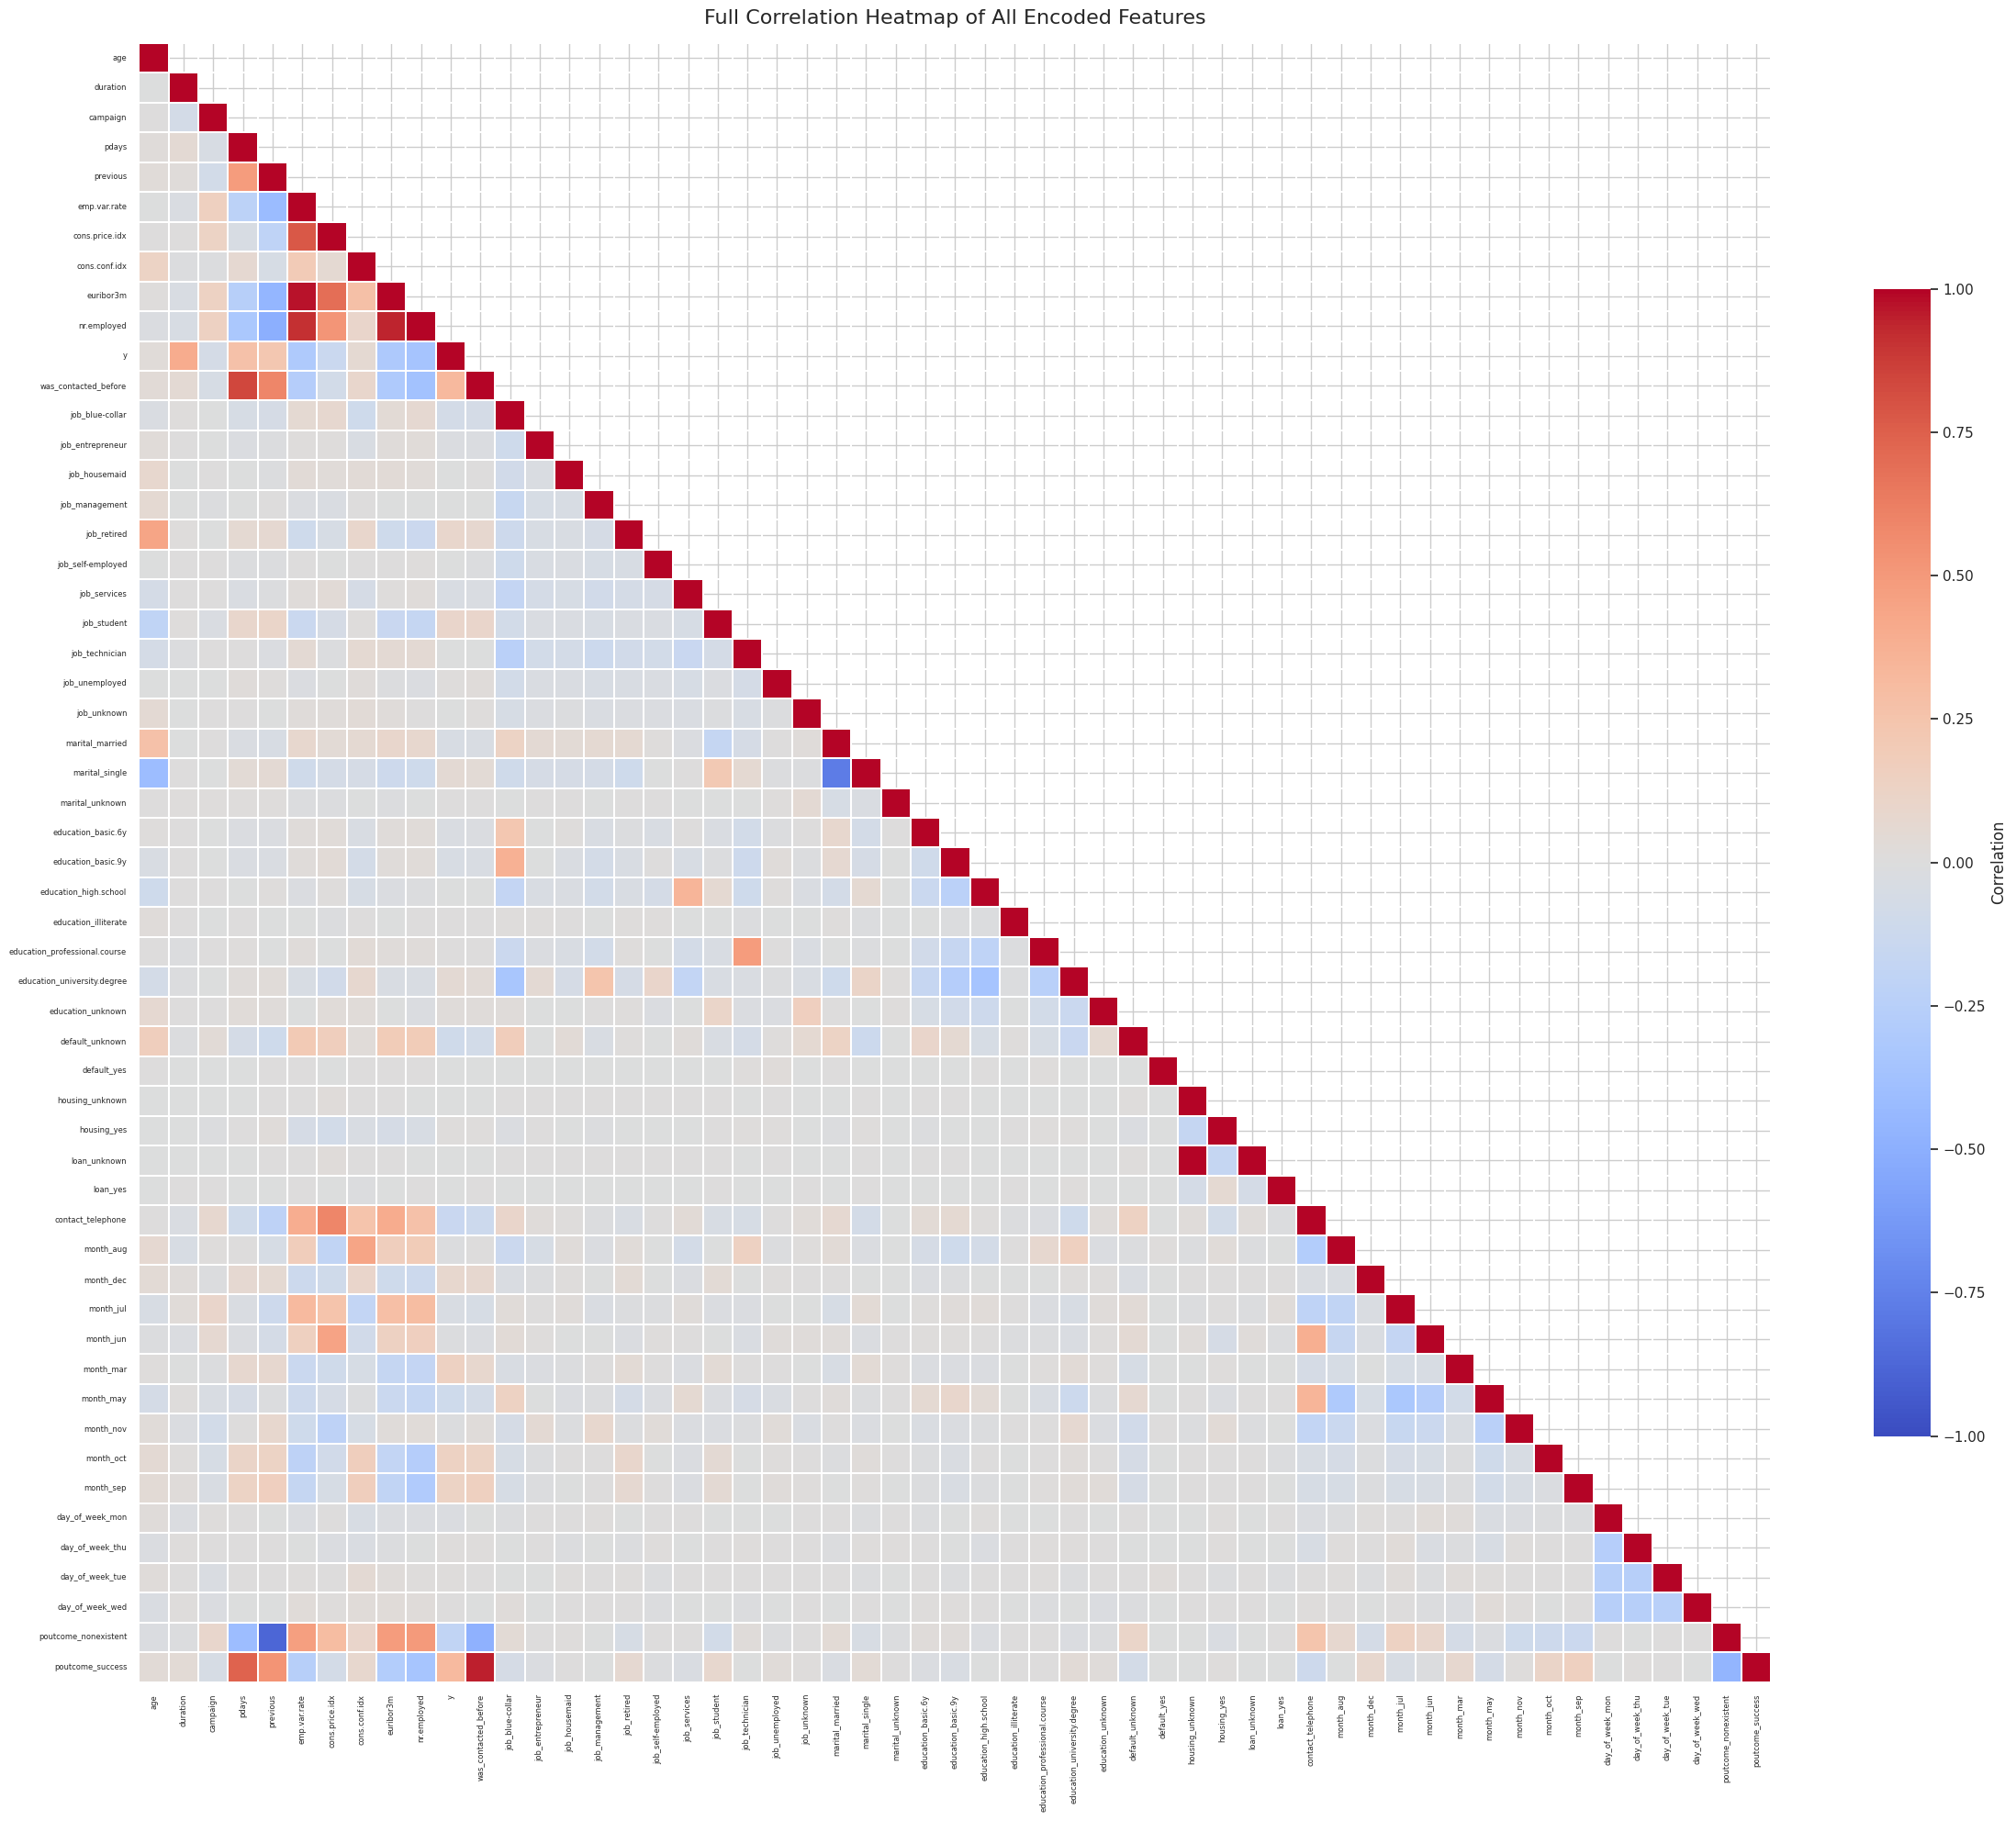

In [ ]:
df_corr = df.copy()

df_corr["was_contacted_before"] = (df_corr["pdays"] != 999).astype(int)
df_corr.loc[df_corr["pdays"] == 999, "pdays"] = 0

df_corr["y"] = df_corr["y"].map({"no": 0, "yes": 1})

corr_categorical = [
    col for col in df_corr.select_dtypes(include="object").columns
    if col != "y"
]

df_corr = pd.get_dummies(
    df_corr,
    columns=corr_categorical,
    drop_first=True,
    dtype=int
)

corr_matrix = df_corr.corr(numeric_only=True)

print("Encoded correlation matrix shape:", corr_matrix.shape)

mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

plt.figure(figsize=(24, 20))

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False,
    linewidths=0.15,
    cbar_kws={"shrink": 0.7, "label": "Correlation"}
)

plt.title(
    "Full Correlation Heatmap of All Encoded Features",
    fontsize=16,
    pad=15
)

plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()


Top 20 features most correlated with target y:


,Correlation with y
duration,0.405297
nr.employed,-0.354669
was_contacted_before,0.324910
poutcome_success,0.316302
euribor3m,-0.307740
emp.var.rate,-0.298289
pdays,0.267115
previous,0.230202
poutcome_nonexistent,-0.193522
contact_telephone,-0.144774


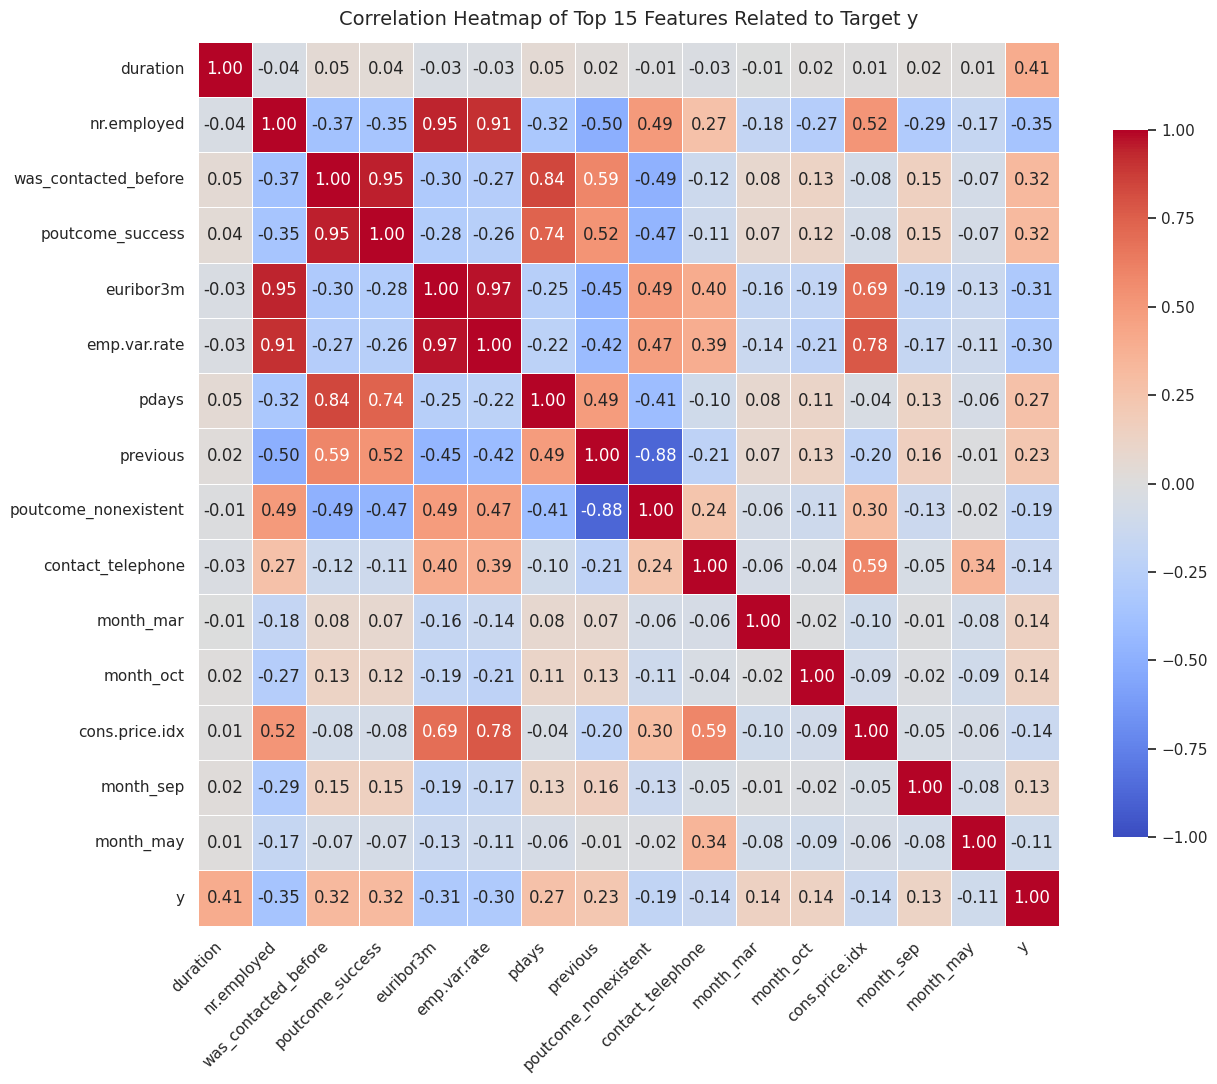

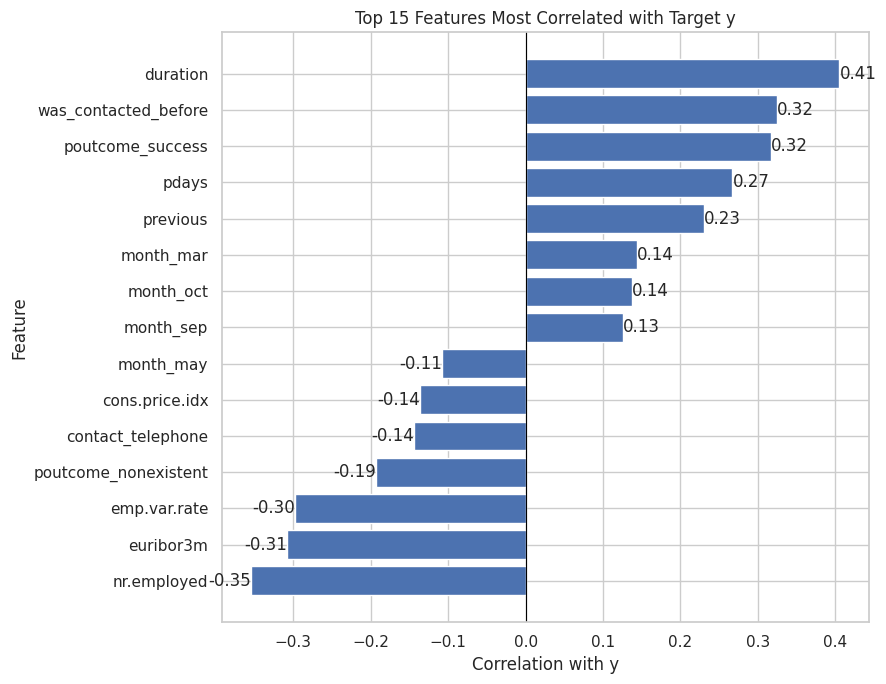

In [ ]:
target_corr = (
    corr_matrix["y"]
    .drop("y")
    .sort_values(key=abs, ascending=False)
)

print("Top 20 features most correlated with target y:")
display(target_corr.head(20).to_frame("Correlation with y"))

top_features = target_corr.head(15).index.tolist()

top_corr_matrix = df_corr[
    top_features + ["y"]
].corr()

plt.figure(figsize=(13, 11))

sns.heatmap(
    top_corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title(
    "Correlation Heatmap of Top 15 Features Related to Target y",
    fontsize=14,
    pad=12
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 7))

top_target_corr = target_corr.head(15).sort_values()

bars = plt.barh(
    top_target_corr.index,
    top_target_corr.values
)
for bar, value in zip(bars, top_target_corr.values):
    plt.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        ha="left" if value >= 0 else "right"
    )

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top 15 Features Most Correlated with Target y")
plt.xlabel("Correlation with y")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [ ]:
#EDA
print("Numerical feature statistics:")
display(df.describe().T)

print("\nCategorical feature statistics:")
display(df.select_dtypes(include="object").describe().T)

Numerical feature statistics:


,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.023800,10.420680,17.000,32.000,38.000,47.000,98.000
duration,41176.0,258.315815,259.305321,0.000,102.000,180.000,319.000,4918.000
campaign,41176.0,2.567879,2.770318,1.000,1.000,2.000,3.000,56.000
pdays,41176.0,962.464810,186.937102,0.000,999.000,999.000,999.000,999.000
previous,41176.0,0.173013,0.494964,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41176.0,0.081922,1.570883,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41176.0,93.575720,0.578839,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41176.0,-40.502863,4.627860,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41176.0,3.621293,1.734437,0.634,1.344,4.857,4.961,5.045
nr.employed,41176.0,5167.034870,72.251364,4963.600,5099.100,5191.000,5228.100,5228.100



Categorical feature statistics:


,count,unique,top,freq
job,41176,12,admin.,10419
marital,41176,4,married,24921
education,41176,8,university.degree,12164
default,41176,3,no,32577
housing,41176,3,yes,21571
loan,41176,3,no,33938
contact,41176,2,cellular,26135
month,41176,10,may,13767
day_of_week,41176,5,thu,8618
poutcome,41176,3,nonexistent,35551


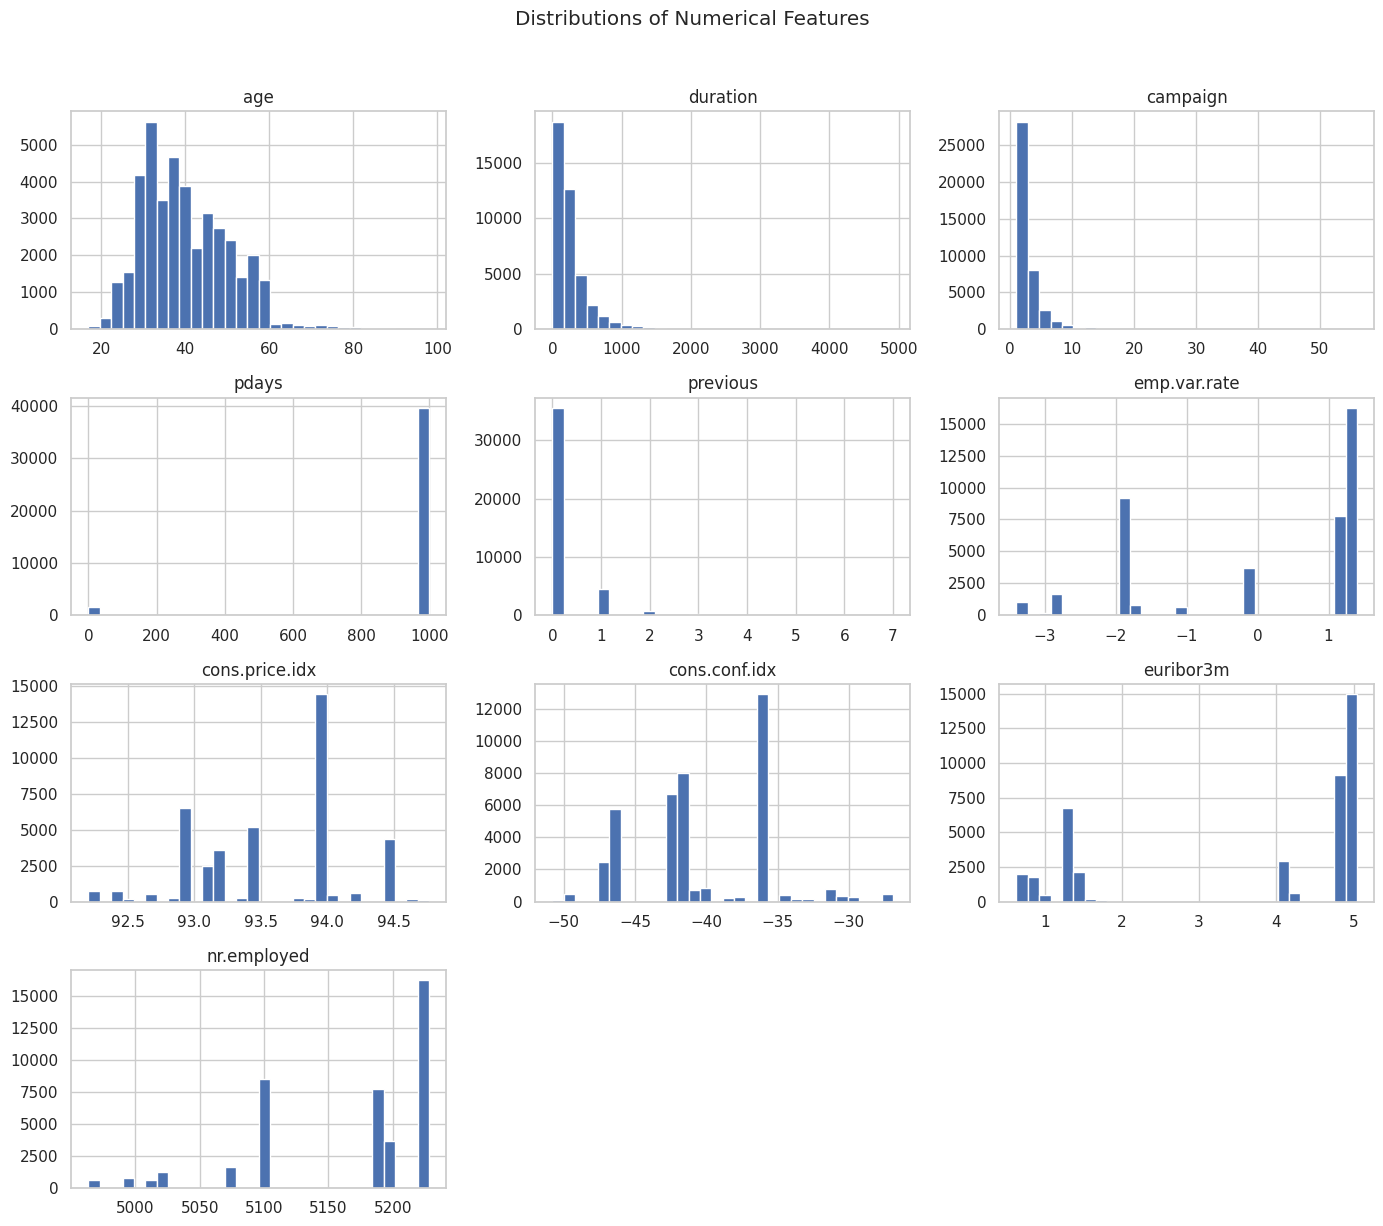

In [ ]:
df[numerical_features].hist(
    figsize=(14, 12),
    bins=30
)

plt.suptitle("Distributions of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()

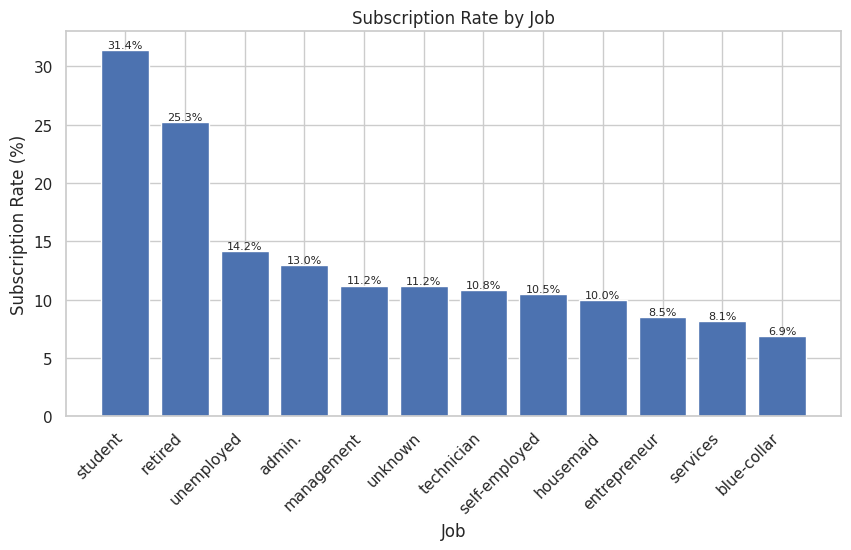

In [ ]:
job_rate = (
    df.groupby("job")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
bars = plt.bar(job_rate.index, job_rate.values)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Subscription Rate (%)")
plt.xlabel("Job")
plt.title("Subscription Rate by Job")
for bar, value in zip(bars, job_rate.values):
    plt.text(bar.get_x() + bar.get_width() / 2, value, f"{value:.1f}%", ha="center", va="bottom", fontsize=8)
plt.show()

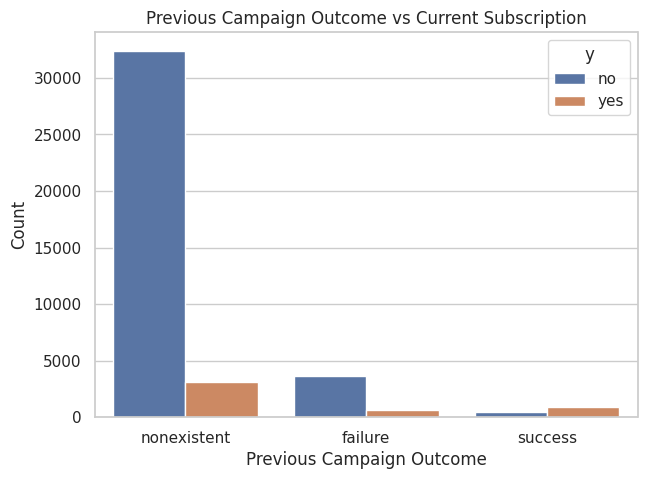

In [ ]:

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="poutcome", hue="y")
plt.title("Previous Campaign Outcome vs Current Subscription")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Count")
plt.show()

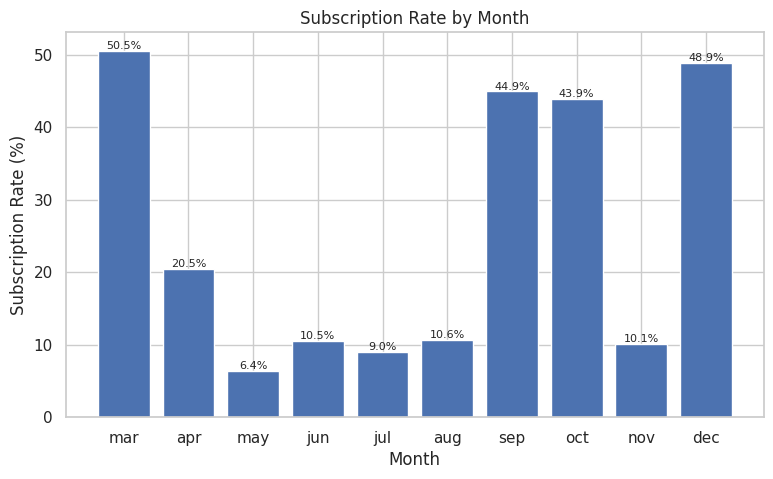

In [ ]:
month_order = [
    "mar", "apr", "may", "jun", "jul",
    "aug", "sep", "oct", "nov", "dec"
]

month_rate = (
    df.groupby("month")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .reindex(month_order)
    .dropna()
)

plt.figure(figsize=(9, 5))
bars = plt.bar(month_rate.index, month_rate.values)
plt.ylabel("Subscription Rate (%)")
plt.xlabel("Month")
plt.title("Subscription Rate by Month")
for bar, value in zip(bars, month_rate.values):
    plt.text(bar.get_x() + bar.get_width() / 2, value, f"{value:.1f}%", ha="center", va="bottom", fontsize=8)
plt.show()

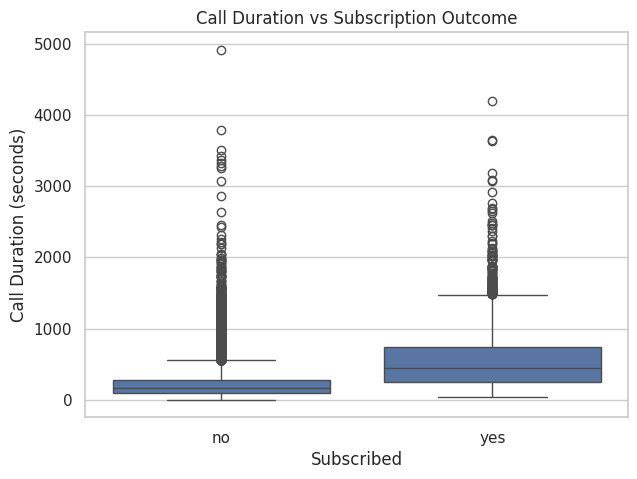

In [ ]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="y", y="duration")
plt.title("Call Duration vs Subscription Outcome")
plt.xlabel("Subscribed")
plt.ylabel("Call Duration (seconds)")
plt.show()

In [ ]:
missing_counts = df.isnull().sum()
print("Actual NaN / empty values:")
display(missing_counts[missing_counts > 0].to_frame("Missing Count"))

if missing_counts.sum() == 0:
    print("No actual NaN or empty values were found.")

print("\nCounts of the category 'unknown':")
unknown_info = []

for col in df.select_dtypes(include="object").columns:
    count = (df[col] == "unknown").sum()
    if count > 0:
        unknown_info.append([
            col,
            count,
            round(count / len(df) * 100, 2)
        ])

unknown_df = pd.DataFrame(
    unknown_info,
    columns=["Column", "Unknown Count", "Percentage"]
)

display(unknown_df)

Actual NaN / empty values:


,Missing Count


No actual NaN or empty values were found.

Counts of the category 'unknown':


,Column,Unknown Count,Percentage
0,job,330,0.80
1,marital,80,0.19
2,education,1730,4.20
3,default,8596,20.88
4,housing,990,2.40
5,loan,990,2.40


In [ ]:
if df["y"].isnull().sum() > 0:
    df = df.dropna(subset=["y"]).reset_index(drop=True)

for col in df.select_dtypes(include=np.number).columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include="object").columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Remaining actual missing values:", df.isnull().sum().sum())

Remaining actual missing values: 0


In [ ]:
#Handle pdays = 999

df["was_contacted_before"] = (df["pdays"] != 999).astype(int)

df.loc[df["pdays"] == 999, "pdays"] = 0

print(df[[
    "pdays",
    "previous",
    "poutcome",
    "was_contacted_before"
]].head(10))

print("\nValue counts:")
print(df["was_contacted_before"].value_counts())

   pdays  previous     poutcome  was_contacted_before
0      0         0  nonexistent                     1
1      0         0  nonexistent                     1
2      0         0  nonexistent                     1
3      0         0  nonexistent                     1
4      0         0  nonexistent                     1
5      0         0  nonexistent                     1
6      0         0  nonexistent                     1
7      0         0  nonexistent                     1
8      0         0  nonexistent                     1
9      0         0  nonexistent                     1

Value counts:
was_contacted_before
1    41176
Name: count, dtype: int64


In [ ]:
# x,y
y = df["y"].map({"no": 0, "yes": 1}).astype(int)

X_raw = df.drop(columns=["y", "duration"])

print("Model input shape before encoding:", X_raw.shape)
print("Target distribution:")
print(y.value_counts())

Model input shape before encoding: (41176, 20)
Target distribution:
y
0    36537
1     4639
Name: count, dtype: int64


In [ ]:
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_raw,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw,
    y_temp,
    test_size=2/3,
    random_state=42,
    stratify=y_temp
)

print("Training size:", len(X_train_raw))
print("Validation size:", len(X_val_raw))
print("Testing size:", len(X_test_raw))
print("Total:", len(X_train_raw) + len(X_val_raw) + len(X_test_raw))

print("\nTraining class ratio:")
print(y_train.value_counts(normalize=True))

print("\nValidation class ratio:")
print(y_val.value_counts(normalize=True))

print("\nTesting class ratio:")
print(y_test.value_counts(normalize=True))

Training size: 28823
Validation size: 4117
Testing size: 8236
Total: 41176

Training class ratio:
y
0    0.887347
1    0.112653
Name: proportion, dtype: float64

Validation class ratio:
y
0    0.887297
1    0.112703
Name: proportion, dtype: float64

Testing class ratio:
y
0    0.887324
1    0.112676
Name: proportion, dtype: float64


In [ ]:
# One-Hot Encoding for training, validation and test data

categorical_cols = X_train_raw.select_dtypes(include="object").columns.tolist()

X_train = pd.get_dummies(
    X_train_raw,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

X_val = pd.get_dummies(
    X_val_raw,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test_raw,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Encoded training shape:", X_train.shape)
print("Encoded validation shape:", X_val.shape)
print("Encoded testing shape:", X_test.shape)

Encoded training shape: (28823, 53)
Encoded validation shape: (4117, 53)
Encoded testing shape: (8236, 53)


In [ ]:
numeric_cols = X_train_raw.select_dtypes(include=np.number).columns.tolist()

numeric_to_scale = [
    col for col in numeric_cols
    if col != "was_contacted_before"
]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_to_scale] = scaler.fit_transform(
    X_train[numeric_to_scale]
)

X_val_scaled[numeric_to_scale] = scaler.transform(
    X_val[numeric_to_scale]
)

X_test_scaled[numeric_to_scale] = scaler.transform(
    X_test[numeric_to_scale]
)

X_train_scaled.head()

,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,was_contacted_before,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,marital_married,marital_single,marital_unknown,education_basic.6y,education_basic.9y,education_high.school,education_illiterate,education_professional.course,education_university.degree,education_unknown,default_unknown,default_yes,housing_unknown,housing_yes,loan_unknown,loan_yes,contact_telephone,month_aug,month_dec,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
27498,1.632401,-0.203357,-0.164942,-0.349305,-0.115904,-0.648967,-0.324618,0.231376,0.398403,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0
20984,0.384367,-0.566537,-0.164942,-0.349305,0.838925,-0.227667,0.950131,0.774643,0.844054,1,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0
34370,-0.863667,-0.566537,-0.164942,1.656278,-1.198042,-1.179046,-1.232066,-1.355792,-0.935789,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0
17255,1.248390,-0.203357,-0.164942,-0.349305,0.838925,0.590761,-0.475859,0.773491,0.844054,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0
15326,-0.863667,-0.203357,-0.164942,-0.349305,0.838925,0.590761,-0.475859,0.770610,0.844054,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0


In [ ]:
knn_validation_results = []

for k in [3, 5, 7, 9, 11, 15, 21, 31]:
    for weights in ["uniform", "distance"]:
        model = KNeighborsClassifier(
            n_neighbors=k,
            weights=weights
        )

        model.fit(X_train_scaled, y_train)
        val_pred = model.predict(X_val_scaled)

        val_accuracy = accuracy_score(y_val, val_pred)

        knn_validation_results.append([
            k,
            weights,
            val_accuracy
        ])

knn_tuning_df = pd.DataFrame(
    knn_validation_results,
    columns=["K", "Weights", "Validation Accuracy"]
)

knn_tuning_df = knn_tuning_df.sort_values(
    ["Validation Accuracy", "K"],
    ascending=[False, True]
).reset_index(drop=True)

display(knn_tuning_df)

best_k = int(knn_tuning_df.iloc[0]["K"])
best_knn_weights = knn_tuning_df.iloc[0]["Weights"]

print("Best K:", best_k)
print("Best weighting method:", best_knn_weights)
print(
    "Best validation accuracy:",
    round(knn_tuning_df.iloc[0]["Validation Accuracy"], 4)
)


,K,Weights,Validation Accuracy
0,31,uniform,0.902356
1,11,uniform,0.901870
2,21,uniform,0.900413
3,9,uniform,0.899684
4,15,uniform,0.899198
5,11,distance,0.898713
6,31,distance,0.898227
7,7,uniform,0.897012
8,21,distance,0.896769
9,9,distance,0.896041


Best K: 31
Best weighting method: uniform
Best validation accuracy: 0.9024


In [ ]:
dt_validation_results = []

depth_values = [3, 4, 5, 6, 7, 8, 10, 12, None]
leaf_values = [1, 5, 10]

for depth in depth_values:
    for leaf in leaf_values:
        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=42
        )

        model.fit(X_train, y_train)
        val_pred = model.predict(X_val)

        val_accuracy = accuracy_score(y_val, val_pred)

        dt_validation_results.append([
            depth,
            leaf,
            val_accuracy
        ])

dt_tuning_df = pd.DataFrame(
    dt_validation_results,
    columns=[
        "Max Depth",
        "Min Samples Leaf",
        "Validation Accuracy"
    ]
)

dt_tuning_df = dt_tuning_df.sort_values(
    "Validation Accuracy",
    ascending=False
).reset_index(drop=True)

display(dt_tuning_df)

best_depth_value = dt_tuning_df.iloc[0]["Max Depth"]
best_depth = (
    None
    if pd.isna(best_depth_value)
    else int(best_depth_value)
)

best_leaf = int(
    dt_tuning_df.iloc[0]["Min Samples Leaf"]
)

print("Best max_depth:", best_depth)
print("Best min_samples_leaf:", best_leaf)
print(
    "Best validation accuracy:",
    round(dt_tuning_df.iloc[0]["Validation Accuracy"], 4)
)


,Max Depth,Min Samples Leaf,Validation Accuracy
0,4.0,10,0.901385
1,3.0,5,0.901142
2,3.0,1,0.901142
3,3.0,10,0.901142
4,4.0,1,0.901142
5,4.0,5,0.901142
6,5.0,1,0.900656
7,5.0,5,0.900656
8,8.0,10,0.900413
9,6.0,10,0.900170


Best max_depth: 4
Best min_samples_leaf: 10
Best validation accuracy: 0.9014


In [ ]:

lr_validation_results = []

for c_value in [0.01, 0.1, 1, 10, 100]:
    model = LogisticRegression(
        C=c_value,
        max_iter=3000,
        random_state=42
    )

    model.fit(X_train_scaled, y_train)
    val_pred = model.predict(X_val_scaled)

    val_accuracy = accuracy_score(y_val, val_pred)
    lr_validation_results.append([c_value, val_accuracy])

lr_tuning_df = pd.DataFrame(
    lr_validation_results,
    columns=["C", "Validation Accuracy"]
)

display(lr_tuning_df)

best_c = float(
    lr_tuning_df
    .sort_values("Validation Accuracy", ascending=False)
    .iloc[0]["C"]
)

print("Best C:", best_c)

,C,Validation Accuracy
0,0.01,0.901385
1,0.10,0.900170
2,1.00,0.899927
3,10.00,0.899441
4,100.00,0.899927


Best C: 0.01


In [ ]:

X_trainval_raw = pd.concat(
    [X_train_raw, X_val_raw],
    axis=0
)

y_trainval = pd.concat(
    [y_train, y_val],
    axis=0
)

X_trainval = pd.get_dummies(
    X_trainval_raw,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

X_test_final = pd.get_dummies(
    X_test_raw,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

X_test_final = X_test_final.reindex(
    columns=X_trainval.columns,
    fill_value=0
)

print("Final training size:", len(X_trainval))
print("Final test size:", len(X_test_final))
print("Final encoded feature count:", X_trainval.shape[1])

Final training size: 32940
Final test size: 8236
Final encoded feature count: 53


In [ ]:
final_scaler = StandardScaler()

X_trainval_scaled = X_trainval.copy()
X_test_final_scaled = X_test_final.copy()

X_trainval_scaled[numeric_to_scale] = final_scaler.fit_transform(
    X_trainval[numeric_to_scale]
)

X_test_final_scaled[numeric_to_scale] = final_scaler.transform(
    X_test_final[numeric_to_scale]
)

print("Scaling completed.")

Scaling completed.


In [ ]:

results = {}
roc_data = {}
predictions = {}
probabilities = {}

def save_and_show_results(name, y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc_score = roc_auc_score(y_true, y_prob)

    results[name] = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "AUC": auc_score
    }

    predictions[name] = y_pred
    probabilities[name] = y_prob

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_data[name] = (fpr, tpr, auc_score)

    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(
        y_true,
        y_pred,
        target_names=["no", "yes"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        display_labels=["no", "yes"],
        cmap="Blues"
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

KNN
              precision    recall  f1-score   support

          no       0.91      0.98      0.95      7308
         yes       0.64      0.23      0.34       928

    accuracy                           0.90      8236
   macro avg       0.78      0.61      0.64      8236
weighted avg       0.88      0.90      0.88      8236



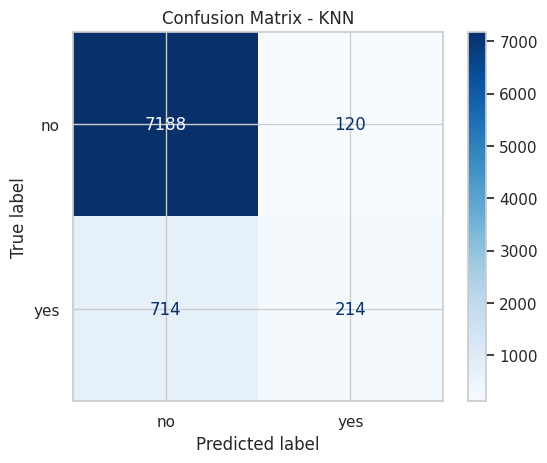

In [ ]:

knn = KNeighborsClassifier(
    n_neighbors=best_k,
    weights=best_knn_weights
)

knn.fit(
    X_trainval_scaled,
    y_trainval
)

knn_pred = knn.predict(
    X_test_final_scaled
)

knn_prob = knn.predict_proba(
    X_test_final_scaled
)[:, 1]

save_and_show_results(
    "KNN",
    y_test,
    knn_pred,
    knn_prob
)


Decision Tree
              precision    recall  f1-score   support

          no       0.90      0.99      0.94      7308
         yes       0.67      0.18      0.28       928

    accuracy                           0.90      8236
   macro avg       0.79      0.58      0.61      8236
weighted avg       0.88      0.90      0.87      8236



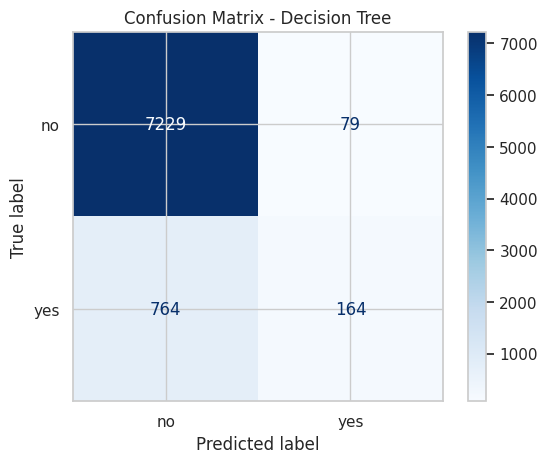

In [ ]:

decision_tree = DecisionTreeClassifier(
    max_depth=best_depth,
    min_samples_leaf=best_leaf,
    random_state=42
)

decision_tree.fit(
    X_trainval,
    y_trainval
)

dt_pred = decision_tree.predict(
    X_test_final
)

dt_prob = decision_tree.predict_proba(
    X_test_final
)[:, 1]

save_and_show_results(
    "Decision Tree",
    y_test,
    dt_pred,
    dt_prob
)


Logistic Regression
              precision    recall  f1-score   support

          no       0.90      0.99      0.95      7308
         yes       0.69      0.18      0.29       928

    accuracy                           0.90      8236
   macro avg       0.80      0.59      0.62      8236
weighted avg       0.88      0.90      0.87      8236



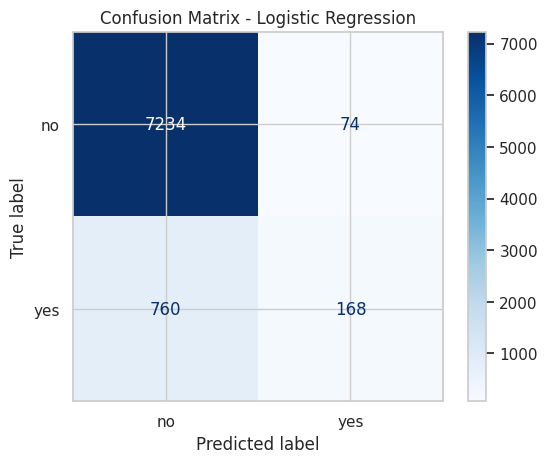

In [ ]:

logistic_regression = LogisticRegression(
    C=best_c,
    max_iter=3000,
    random_state=42
)

logistic_regression.fit(
    X_trainval_scaled,
    y_trainval
)

lr_pred = logistic_regression.predict(
    X_test_final_scaled
)

lr_prob = logistic_regression.predict_proba(
    X_test_final_scaled
)[:, 1]

save_and_show_results(
    "Logistic Regression",
    y_test,
    lr_pred,
    lr_prob
)

Naive Bayes
              precision    recall  f1-score   support

          no       0.93      0.92      0.93      7308
         yes       0.42      0.44      0.43       928

    accuracy                           0.87      8236
   macro avg       0.67      0.68      0.68      8236
weighted avg       0.87      0.87      0.87      8236



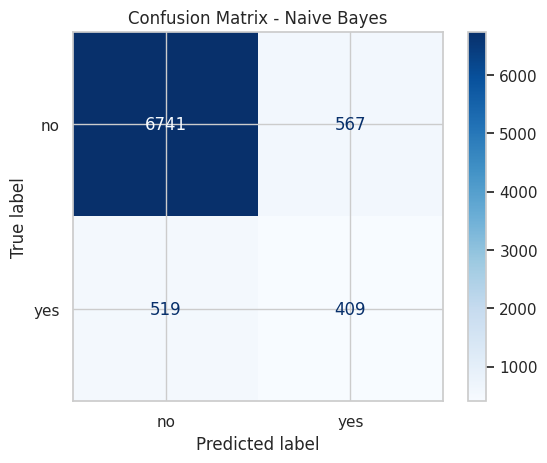

In [ ]:
naive_bayes = GaussianNB()

naive_bayes.fit(
    X_trainval,
    y_trainval
)

nb_pred = naive_bayes.predict(
    X_test_final
)

nb_prob = naive_bayes.predict_proba(
    X_test_final
)[:, 1]

save_and_show_results(
    "Naive Bayes",
    y_test,
    nb_pred,
    nb_prob
)

In [ ]:

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

X_nn_train = X_trainval_scaled.to_numpy(dtype=np.float32)
X_nn_test = X_test_final_scaled.to_numpy(dtype=np.float32)

y_nn_train = y_trainval.to_numpy(dtype=np.float32)

nn_model = Sequential([
    tf.keras.Input(shape=(X_nn_train.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

nn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

nn_model.summary()

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history = nn_model.fit(
    X_nn_train,
    y_nn_train,
    epochs=30,
    batch_size=128,
    validation_split=0.10,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

print(
    "Training stopped after",
    len(history.history["loss"]),
    "epochs."
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,569 (21.75 KB)

 Trainable params: 5,569 (21.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
232/232 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8918 - loss: 0.3085 - val_accuracy: 0.9029 - val_loss: 0.2787
Epoch 2/30
232/232 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9000 - loss: 0.2788 - val_accuracy: 0.9029 - val_loss: 0.2758
Epoch 3/30
232/232 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9011 - loss: 0.2757 - val_accuracy: 0.9029 - val_loss: 0.2741
Epoch 4/30
232/232 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9014 - loss: 0.2737 - val_accuracy: 0.9026 - val_loss: 0.2731
Epoch 5/30
232/232 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9017 - loss: 0.2720 - val_accuracy: 0.9032 - val_loss: 0.2728
Epoch 6/30
232/232 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9024 - loss: 0.2706 - val_accuracy: 0.9022 - val_loss: 0.2725
Epoch 7/30
232/232 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9031 - loss: 0.2692 - val_accuracy: 0.9019 - val_loss: 0.2723
Epoch 8/30
232/232 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9032 - loss: 0.2679 - val_accuracy: 0.

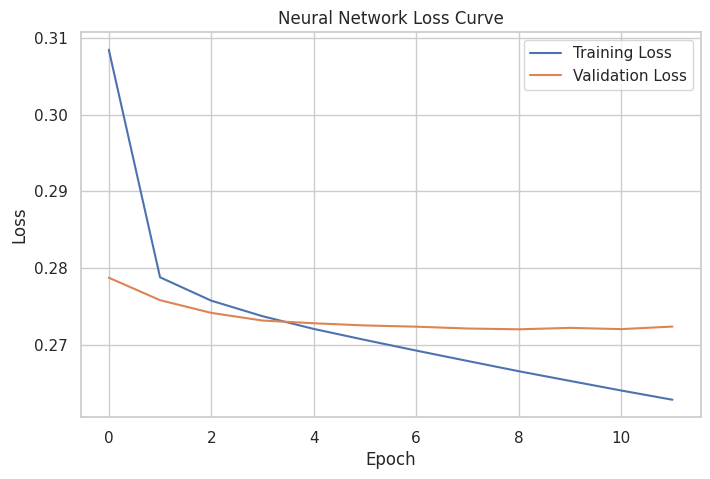

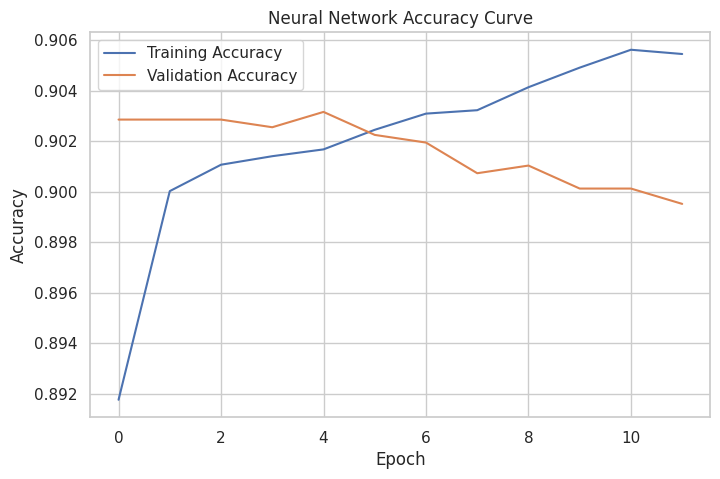

In [ ]:

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Neural Network Loss Curve")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Neural Network Accuracy Curve")
plt.legend()
plt.show()

Neural Network
              precision    recall  f1-score   support

          no       0.91      0.98      0.95      7308
         yes       0.64      0.24      0.35       928

    accuracy                           0.90      8236
   macro avg       0.77      0.61      0.65      8236
weighted avg       0.88      0.90      0.88      8236



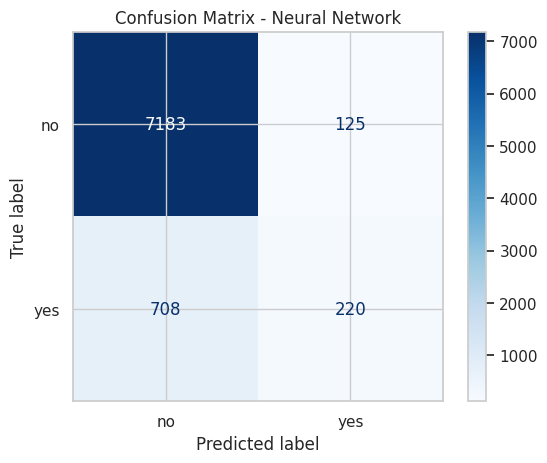

In [ ]:

nn_prob = nn_model.predict(
    X_nn_test,
    verbose=0
).ravel()

nn_pred = (nn_prob >= 0.5).astype(int)

save_and_show_results(
    "Neural Network",
    y_test,
    nn_pred,
    nn_prob
)

,K,SSE,Silhouette Score
0,2,316485.6670,0.3131
1,3,290818.7978,0.2740
2,4,263189.4421,0.2977
3,5,246893.5833,0.1567
4,6,230053.0265,0.1604
5,7,217479.8060,0.1723
6,8,207284.2902,0.1558


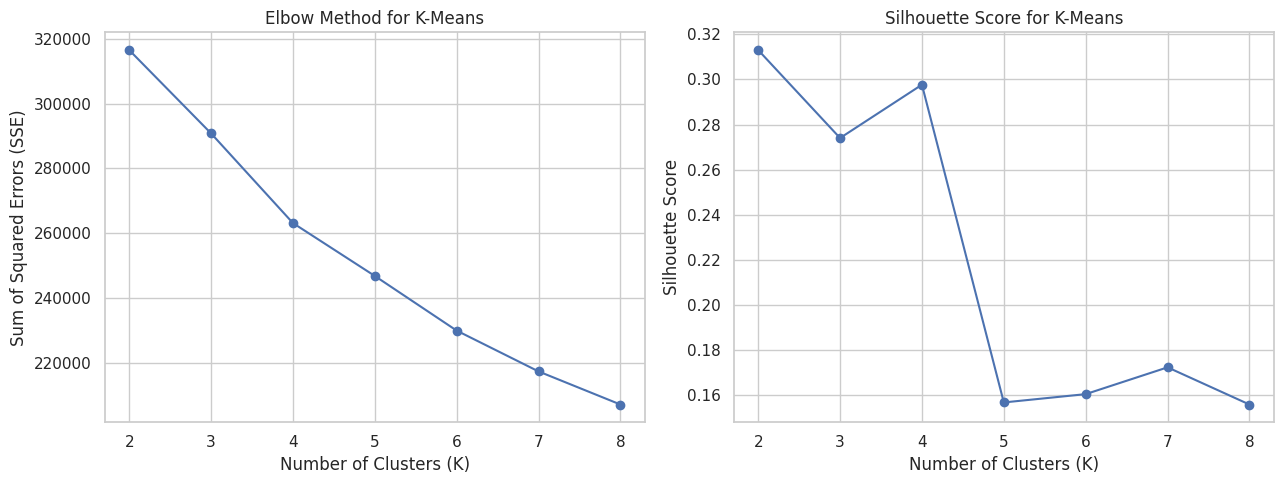

Selected K based on the highest silhouette score: 2


In [ ]:

k_values = range(2, 9)
sse = []
silhouette_scores = []

silhouette_sample_size = min(5000, len(X_trainval_scaled))
rng = np.random.RandomState(42)
sample_indices = rng.choice(
    len(X_trainval_scaled),
    size=silhouette_sample_size,
    replace=False
)
X_kmeans_sample = X_trainval_scaled.iloc[sample_indices]

for k in k_values:
    kmeans_temp = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans_temp.fit(X_trainval_scaled)
    sse.append(kmeans_temp.inertia_)

    sample_labels = kmeans_temp.predict(X_kmeans_sample)
    silhouette_scores.append(
        silhouette_score(X_kmeans_sample, sample_labels)
    )

k_selection_df = pd.DataFrame({
    "K": list(k_values),
    "SSE": sse,
    "Silhouette Score": silhouette_scores
})

best_kmeans_k = int(
    k_selection_df.loc[
        k_selection_df["Silhouette Score"].idxmax(),
        "K"
    ]
)

display(k_selection_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(k_selection_df["K"], k_selection_df["SSE"], marker="o")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Sum of Squared Errors (SSE)")
axes[0].set_title("Elbow Method for K-Means")

axes[1].plot(
    k_selection_df["K"],
    k_selection_df["Silhouette Score"],
    marker="o"
)
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score for K-Means")

plt.tight_layout()
plt.show()

print("Selected K based on the highest silhouette score:", best_kmeans_k)


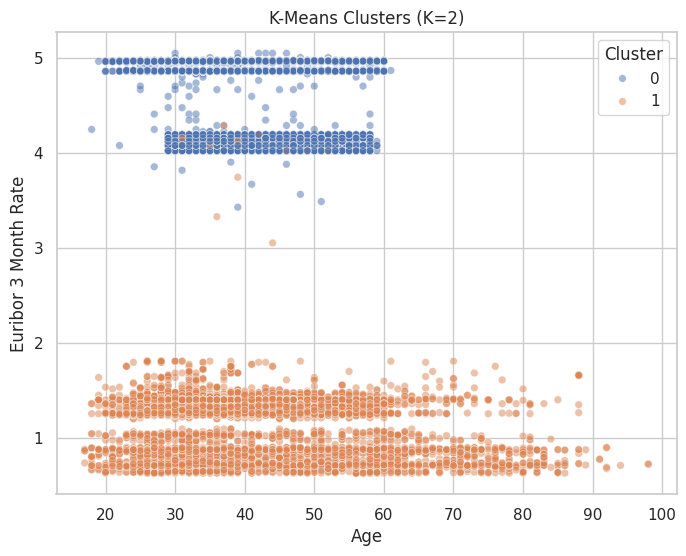

Number of observations in each cluster:


,Count
Cluster,
0,22078
1,10862


In [ ]:

kmeans = KMeans(
    n_clusters=best_kmeans_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(
    X_trainval_scaled
)

cluster_plot = (
    X_trainval_raw[["age", "euribor3m"]]
    .reset_index(drop=True)
    .copy()
)

cluster_plot["Cluster"] = cluster_labels.astype(str)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=cluster_plot,
    x="age",
    y="euribor3m",
    hue="Cluster",
    alpha=0.5,
    s=30
)

plt.title(f"K-Means Clusters (K={best_kmeans_k})")
plt.xlabel("Age")
plt.ylabel("Euribor 3 Month Rate")
plt.show()

print("Number of observations in each cluster:")
display(
    pd.Series(cluster_labels, name="Cluster")
    .value_counts()
    .sort_index()
    .to_frame("Count")
)


In [ ]:

cluster_comparison = pd.DataFrame({
    "Cluster": cluster_labels,
    "Actual y": y_trainval.reset_index(drop=True)
})

cluster_comparison["Actual y"] = cluster_comparison["Actual y"].map({
    0: "no",
    1: "yes"
})

print("Cluster vs actual class:")
display(pd.crosstab(
    cluster_comparison["Cluster"],
    cluster_comparison["Actual y"]
))

Cluster vs actual class:


Actual y,no,yes
Cluster,,
0,20991,1087
1,8238,2624


## 6. Model Selection / Comparison Analysis

In [ ]:

results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

display(results_df.round(4))

majority_baseline = y_test.value_counts(normalize=True).max()

print(
    f"Majority-class baseline accuracy: "
    f"{majority_baseline:.4f}"
)

,Accuracy,Precision,Recall,F1-Score,AUC
Neural Network,0.8989,0.6377,0.2371,0.3456,0.7991
KNN,0.8987,0.6407,0.2306,0.3391,0.7890
Logistic Regression,0.8987,0.6942,0.1810,0.2872,0.8021
Decision Tree,0.8976,0.6749,0.1767,0.2801,0.7709
Naive Bayes,0.8681,0.4191,0.4407,0.4296,0.7779


Majority-class baseline accuracy: 0.8873


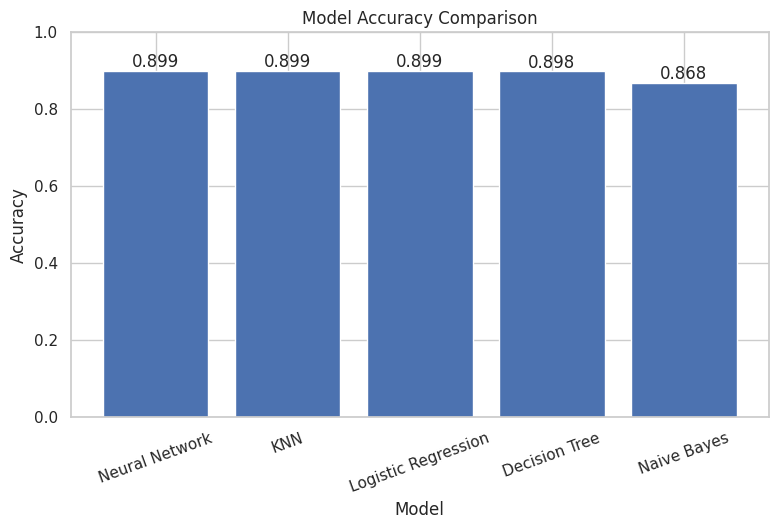

In [ ]:

plt.figure(figsize=(9, 5))

ax = plt.bar(
    results_df.index,
    results_df["Accuracy"]
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)

for bar, value in zip(ax, results_df["Accuracy"]):
    plt.text(bar.get_x() + bar.get_width() / 2, value, f"{value:.3f}", ha="center", va="bottom")

plt.show()

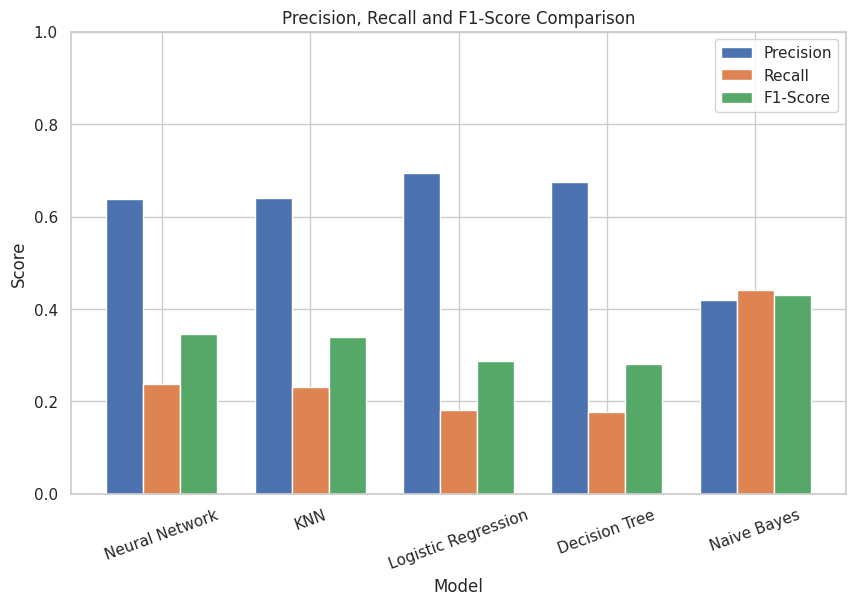

In [ ]:

metric_df = (
    results_df[["Precision", "Recall", "F1-Score"]]
    .reset_index()
    .rename(columns={"index": "Model"})
    .melt(
        id_vars="Model",
        var_name="Metric",
        value_name="Score"
    )
)

plt.figure(figsize=(10, 6))

metric_names = ["Precision", "Recall", "F1-Score"]
x_positions = np.arange(len(results_df.index))
bar_width = 0.25
for offset, metric in enumerate(metric_names):
    values = results_df[metric].to_numpy()
    plt.bar(
        x_positions + (offset - 1) * bar_width,
        values,
        width=bar_width,
        label=metric
    )
plt.xticks(x_positions, results_df.index, rotation=20)
plt.legend()

plt.title("Precision, Recall and F1-Score Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.show()

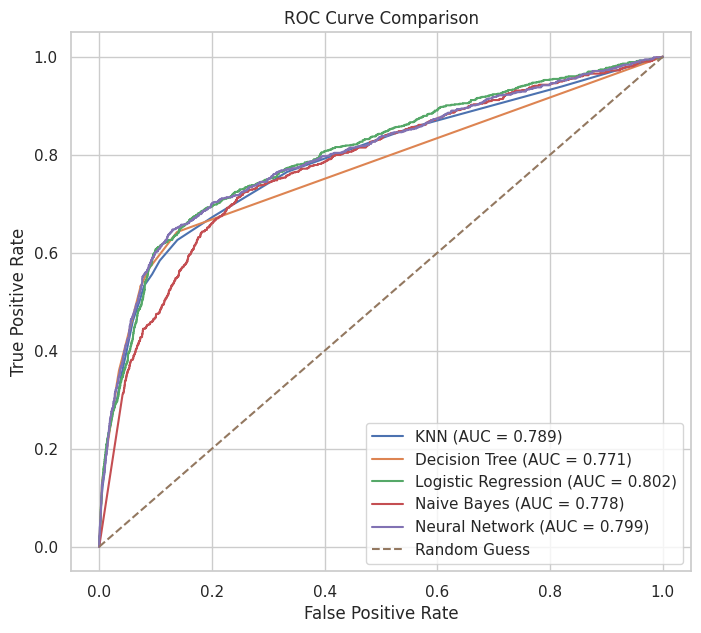

AUC scores:


,AUC
Logistic Regression,0.8021
Neural Network,0.7991
KNN,0.7890
Naive Bayes,0.7779
Decision Tree,0.7709


In [ ]:

plt.figure(figsize=(8, 7))

for name, (fpr, tpr, auc_score) in roc_data.items():
    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guess"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

print("AUC scores:")
display(
    results_df[["AUC"]]
    .sort_values("AUC", ascending=False)
    .round(4)
)

In [ ]:

rounded_accuracy = results_df["Accuracy"].round(4)
best_display_accuracy = rounded_accuracy.max()

top_accuracy_models = results_df[
    rounded_accuracy == best_display_accuracy
].index.tolist()

best_auc_model = results_df["AUC"].idxmax()
best_recall_model = results_df["Recall"].idxmax()
best_f1_model = results_df["F1-Score"].idxmax()
best_precision_model = results_df["Precision"].idxmax()

print("Highest displayed test accuracy:")
print(
    ", ".join(top_accuracy_models),
    f"({best_display_accuracy:.4f})"
)

print(
    f"Highest AUC: {best_auc_model} "
    f"({results_df.loc[best_auc_model, 'AUC']:.4f})"
)

print(
    f"Highest Precision: {best_precision_model} "
    f"({results_df.loc[best_precision_model, 'Precision']:.4f})"
)

print(
    f"Highest Recall: {best_recall_model} "
    f"({results_df.loc[best_recall_model, 'Recall']:.4f})"
)

print(
    f"Highest F1-Score: {best_f1_model} "
    f"({results_df.loc[best_f1_model, 'F1-Score']:.4f})"
)

print(
    "\nInterpretation: There is no single model that is automatically "
    "best for every metric. Because the dataset is imbalanced, accuracy "
    "must be discussed together with precision, recall, F1-score and AUC."
)


Highest displayed test accuracy:
Neural Network (0.8989)
Highest AUC: Logistic Regression (0.8021)
Highest Precision: Logistic Regression (0.6942)
Highest Recall: Naive Bayes (0.4407)
Highest F1-Score: Naive Bayes (0.4296)

Interpretation: There is no single model that is automatically best for every metric. Because the dataset is imbalanced, accuracy must be discussed together with precision, recall, F1-score and AUC.


In [ ]:

print("Final cleaned dataset rows:", len(df))
print("Final 80% training rows:", len(X_trainval))
print("Final 20% test rows:", len(X_test_final))
print("Train + Test:", len(X_trainval) + len(X_test_final))
print("Final number of model features:", X_trainval.shape[1])

train_fraction = len(X_trainval) / len(df)
test_fraction = len(X_test_final) / len(df)
train_positive_rate = y_trainval.mean()
test_positive_rate = y_test.mean()

assert len(X_trainval) + len(X_test_final) == len(df)
assert abs(train_fraction - 0.80) < 0.001
assert abs(test_fraction - 0.20) < 0.001
assert abs(train_positive_rate - test_positive_rate) < 0.005

assert "duration" not in X_trainval.columns
assert "y" not in X_trainval.columns
assert df.isnull().sum().sum() == 0
assert set(y.unique()) == {0, 1}
assert list(X_trainval.columns) == list(X_test_final.columns)

required_models = {
    "KNN",
    "Decision Tree",
    "Logistic Regression",
    "Naive Bayes",
    "Neural Network"
}
assert required_models.issubset(set(results.keys()))

required_metrics = {
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "AUC"
}
assert required_metrics.issubset(set(results_df.columns))
assert len(roc_data) == len(required_models)
assert len(predictions) == len(required_models)
assert len(probabilities) == len(required_models)

assert "best_kmeans_k" in globals()
assert best_kmeans_k >= 2
assert len(cluster_labels) == len(X_trainval_scaled)

print("Final split ratio:", f"{train_fraction:.2%} train / {test_fraction:.2%} test")
print("Train positive rate:", f"{train_positive_rate:.4%}")
print("Test positive rate:", f"{test_positive_rate:.4%}")
print("Required supervised models: PASSED")
print("Required comparison metrics: PASSED")
print("K-Means cluster selection: PASSED")
print("All final sanity checks passed.")


Final cleaned dataset rows: 41176
Final 80% training rows: 32940
Final 20% test rows: 8236
Train + Test: 41176
Final number of model features: 53
Final split ratio: 80.00% train / 20.00% test
Train positive rate: 11.2659%
Test positive rate: 11.2676%
Required supervised models: PASSED
Required comparison metrics: PASSED
K-Means cluster selection: PASSED
All final sanity checks passed.
